# 1층 · 생성형 AI 실습

프롬프트를 AI에게 보내 받은 파이썬 코드입니다. 위에서부터 셀을 차례로 실행해 보세요.
데이터는 GitHub 저장소에서 바로 불러옵니다.

저장된 결과는 Python 3.13.18 · pandas 3.0.5 · scikit-learn 1.9.1 · NumPy 2.5.3 · matplotlib 3.11.2 로 실행한 것입니다. Colab에서는 라이브러리 버전에 따라 소수점이 조금 다를 수 있습니다.

## 실습 1 · 규칙 vs 머신러닝, 스팸 메일 8통으로 비교하기

**프롬프트**

> 파이썬 초보입니다. 메일 8통(스팸 4, 정상 4)으로 작은 예제를 만들어 주세요.
> ① “무료”가 있으면 스팸이라는 규칙
> ② 단어를 세어 배우는 머신러닝(나이브 베이즈)
> 새 메일 3통을 두 방법으로 판정해 나란히 보여 주세요.

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB

# 메일 8통과 정답 (1 = 스팸, 0 = 정상)
mails = ["무료 쿠폰 당첨 지금 클릭", "회의 자료 공유드립니다",
         "할인 이벤트 무료 배송", "내일 점심 약속 확인",
         "당첨 축하 상금 수령", "보고서 초안 검토 부탁",
         "무료 체험 지금 신청", "프로젝트 일정 변경 안내"]
labels = [1, 0, 1, 0, 1, 0, 1, 0]

# ① 사람이 정한 규칙
def rule(text):
    return 1 if "무료" in text else 0

# ② 머신러닝: 단어 개수를 세어 학습
vec = CountVectorizer()
model = MultinomialNB().fit(vec.fit_transform(mails), labels)

name = {1: "스팸", 0: "정상"}
for t in ["상금 당첨 확인 바랍니다", "무료 회의실 예약 안내", "일정 공유드립니다"]:
    ml = model.predict(vec.transform([t]))[0]
    print(t, "→ 규칙:", name[rule(t)], "/ 머신러닝:", name[ml])

상금 당첨 확인 바랍니다 → 규칙: 정상 / 머신러닝: 스팸
무료 회의실 예약 안내 → 규칙: 스팸 / 머신러닝: 스팸
일정 공유드립니다 → 규칙: 정상 / 머신러닝: 정상


**박사의 한 줄 판단** — ‘무료’가 없는 당첨 메일은 규칙이 놓치고 머신러닝이 잡았습니다. 하지만 정상일 수도 있는 ‘무료 회의실 예약 안내’는 둘 다 스팸이라 했어요. 메일 8통으로 배운 결과라 아직 믿기엔 이릅니다.

## 실습 2 · 처음 받은 데이터 파일 열어 보기

**프롬프트**

> rides.csv라는 택시 이용 데이터가 있어요. 파이썬으로 불러와서
> ① 몇 행·몇 열인지 ② 처음 5줄 ③ 이탈(churned) 손님 수를 보여 주고
> 요금(fare) 분포를 그래프로 그려 주세요. 그래프 글자는 영어로 해 주세요.

행, 열: (1200, 7)
   distance_km  duration_min  hour      city  is_weekend   fare  churned
0         2.50          18.8     6  Hangzhou           0   7609        0
1        11.42          42.9     8   Beijing           0  19088        1
2        14.19          42.8    10  Shanghai           0  21901        0
3        13.39          39.2    21   Beijing           0  19265        1
4         8.58          28.5    15  Hangzhou           0  15261        0
churned
0    982
1    218
Name: count, dtype: int64


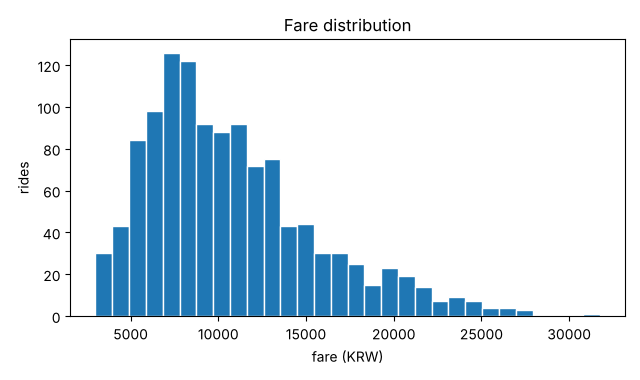

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/adminmrobo/python_machine_learning_lab/main/data/rides.csv"
df = pd.read_csv(url)

print("행, 열:", df.shape)
print(df.head())
print(df["churned"].value_counts())   # 0 = 남은 손님, 1 = 떠난 손님

df["fare"].plot.hist(bins=30, edgecolor="white")
plt.xlabel("fare (KRW)"); plt.ylabel("rides"); plt.title("Fare distribution")
plt.show()

**박사의 한 줄 판단** — 1,200건 중 떠난 손님은 218명(약 18%)입니다. 정답이 한쪽으로 쏠려 있다는 것을 처음부터 알아 두면 2층의 ‘정확도 함정’을 피할 수 있어요.